# Midterm Project — Comparing Three Language Models on Tiny Shakespeare

**Task:** character-level language modeling — given the previous characters, predict the next one.

**Models compared (same data, same vocabulary, same training budget, same evaluation batches):**

1. **Bigram model** — predicts the next character from the current character only.
2. **LSTM** — a 2-layer recurrent network that carries a hidden state through the context (no attention).
3. **Small transformer** — token + positional embeddings, causal multi-head self-attention, feedforward layers, output layer.

The notebook writes every result it produces (tables, plots, generated samples) to `results/`, so the GitHub repository can include them directly.

> **Runtime:** use a GPU in Colab (*Runtime → Change runtime type → T4 GPU*). On CPU everything still works, but training takes roughly 15–25 minutes in total instead of a few minutes.

## 1. Setup and configuration

In [1]:
import math
import os
import random
import time
import urllib.request
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 1337


def set_seed(seed=SEED):
    """Seed Python, NumPy and PyTorch so every run is reproducible.

    Args:
        seed (int): Random seed.

    Returns:
        None.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
os.makedirs('data', exist_ok=True)
os.makedirs('results', exist_ok=True)


@dataclass
class Config:
    """Settings shared by all three models so the comparison is fair."""
    block_size: int = 128      # context length (characters) for LSTM and transformer
    batch_size: int = 64
    max_iters: int = 3000      # identical optimisation budget for every model
    eval_interval: int = 250
    eval_batches: int = 40     # fixed validation/train windows reused for every model
    grad_clip: float = 1.0
    sample_chars: int = 500
    temperature: float = 0.8


CFG = Config()
print(f"Device: {DEVICE}")
print(CFG)

Device: cuda
Config(block_size=128, batch_size=64, max_iters=3000, eval_interval=250, eval_batches=40, grad_clip=1.0, sample_chars=500, temperature=0.8)


## 2. Dataset: Tiny Shakespeare

Tiny Shakespeare (~1.1M characters of Shakespeare's plays) is downloaded from Andrej Karpathy's `char-rnn` repository. The text is used as-is: no cleaning is needed for character-level modeling, and keeping case and punctuation lets the models learn the play format (speaker names in capitals, line breaks, colons).

The first 90% of the text is the training set and the last 10% the validation set. A contiguous split (rather than random sentences) means the validation text comes from scenes the models never saw.

In [2]:
DATA_URL = ('https://raw.githubusercontent.com/karpathy/char-rnn/master/'
            'data/tinyshakespeare/input.txt')
DATA_PATH = 'data/input.txt'

if not os.path.exists(DATA_PATH):
    print("Downloading Tiny Shakespeare...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

with open(DATA_PATH, encoding='utf-8') as f:
    text = f.read()

# Character-level vocabulary built from the full text (65 characters).
chars = sorted(set(text))
VOCAB_SIZE = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}


def encode(s):
    """Convert a string to a list of character indices.

    Args:
        s (str): Input text; every character must be in the vocabulary.

    Returns:
        list[int]: Character indices.
    """
    return [stoi[c] for c in s]


def decode(indices):
    """Convert a list of character indices back to a string.

    Args:
        indices (list[int]): Character indices.

    Returns:
        str: Decoded text.
    """
    return ''.join(itos[i] for i in indices)


data = torch.tensor(encode(text), dtype=torch.long)
split = int(0.9 * len(data))
train_data, val_data = data[:split], data[split:]

print(f"Characters in corpus: {len(text):,}")
print(f"Vocabulary size:      {VOCAB_SIZE}")
print(f"Train / validation:   {len(train_data):,} / {len(val_data):,} characters")
print("\nFirst 250 characters:\n" + text[:250])

Characters in corpus: 1,115,394
Vocabulary size:      65
Train / validation:   1,003,854 / 111,540 characters

First 250 characters:
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.



## 3. Shared batching, training and evaluation

Every model uses **the same** functions below, so differences in the results come from the architecture, not the pipeline:

- `get_batch` samples random windows of `block_size` characters; the target is the same window shifted one character to the right.
- Evaluation uses a **fixed** set of train and validation windows created once with a fixed seed, so all three models are scored on identical text.
- `train_model` uses AdamW, gradient clipping, and the same number of steps for every model. Training time counts only optimisation steps (evaluation time is excluded), with CUDA synchronised so GPU timings are accurate.
- All models share one interface: `model(idx, targets) -> (logits, loss)`, so a single `generate` function samples from any of them.

In [3]:
def get_batch(split, batch_size=CFG.batch_size, block_size=CFG.block_size, generator=None):
    """Sample a batch of (input, target) windows from one split.

    Args:
        split      (str):  'train' or 'val'.
        batch_size (int):  Number of windows.
        block_size (int):  Window length in characters.
        generator  (torch.Generator | None): Optional RNG for fixed batches.

    Returns:
        tuple[torch.Tensor, torch.Tensor]: x and y, each (batch_size, block_size);
            y is x shifted one character to the right.

    Raises:
        ValueError: If split is not 'train' or 'val'.
    """
    if split not in ('train', 'val'):
        raise ValueError(f"split must be 'train' or 'val', got {split!r}")
    source = train_data if split == 'train' else val_data
    starts = torch.randint(len(source) - block_size - 1, (batch_size,), generator=generator)
    x = torch.stack([source[i:i + block_size] for i in starts])
    y = torch.stack([source[i + 1:i + block_size + 1] for i in starts])
    return x.to(DEVICE), y.to(DEVICE)


# Fixed evaluation windows, created once and reused for every model.
_eval_rng = torch.Generator().manual_seed(2024)
EVAL_BATCHES = {split: [get_batch(split, generator=_eval_rng) for _ in range(CFG.eval_batches)]
                for split in ('train', 'val')}


@torch.no_grad()
def estimate_loss(model):
    """Average cross-entropy on the fixed train and validation windows.

    Args:
        model (nn.Module): Language model returning (logits, loss).

    Returns:
        dict[str, float]: {'train': loss, 'val': loss} in nats per character.
    """
    model.eval()
    losses = {}
    for split, batches in EVAL_BATCHES.items():
        losses[split] = float(np.mean([model(x, y)[1].item() for x, y in batches]))
    model.train()
    return losses


def _sync():
    """Wait for queued GPU work so wall-clock timings are accurate.

    Returns:
        None.
    """
    if DEVICE == 'cuda':
        torch.cuda.synchronize()


def train_model(model, name, lr, max_iters=CFG.max_iters):
    """Train a language model with the shared loop and record its history.

    Args:
        model     (nn.Module): Model to train (modified in place).
        name      (str):       Display name.
        lr        (float):     AdamW learning rate.
        max_iters (int):       Number of optimisation steps.

    Returns:
        dict: {'name', 'steps', 'train_loss', 'val_loss', 'train_time_s', 'params'},
            where the loss lists hold one value per evaluation point.
    """
    model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    history = {'name': name, 'steps': [], 'train_loss': [], 'val_loss': [],
               'params': sum(p.numel() for p in model.parameters())}
    train_time = 0.0

    for step in range(max_iters + 1):
        if step % CFG.eval_interval == 0 or step == max_iters:
            losses = estimate_loss(model)
            history['steps'].append(step)
            history['train_loss'].append(losses['train'])
            history['val_loss'].append(losses['val'])
            print(f"[{name}] step {step:5d}  train {losses['train']:.4f}  val {losses['val']:.4f}")
        if step == max_iters:
            break

        x, y = get_batch('train')
        _sync()
        t0 = time.perf_counter()
        _, loss = model(x, y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.grad_clip)
        optimizer.step()
        _sync()
        train_time += time.perf_counter() - t0   # optimisation time only

    history['train_time_s'] = train_time
    return history


@torch.no_grad()
def generate(model, prompt='\n', n_chars=CFG.sample_chars, context_len=CFG.block_size,
             temperature=CFG.temperature, seed=SEED):
    """Sample text from any of the three models.

    Args:
        model       (nn.Module): Trained language model.
        prompt      (str):       Starting text.
        n_chars     (int):       Number of characters to generate.
        context_len (int):       Maximum context passed to the model.
        temperature (float):     Softmax temperature (< 1 is more conservative).
        seed        (int):       Sampling seed, identical for every model.

    Returns:
        str: The prompt followed by the generated characters.

    Raises:
        ValueError: If temperature is not positive.
    """
    if temperature <= 0:
        raise ValueError("temperature must be positive")
    model.eval()
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=DEVICE)
    for _ in range(n_chars):
        logits, _ = model(idx[:, -context_len:])
        probs = F.softmax(logits[:, -1, :] / temperature, dim=-1)
        idx = torch.cat([idx, torch.multinomial(probs, 1, generator=g)], dim=1)
    model.train()
    return decode(idx[0].tolist())

## 4. Model 1 — Bigram model

The bigram model is a single $V \times V$ table: row $i$ holds the logits for the character that follows character $i$. It uses **only the current character** and ignores everything before it, so it can learn which letters tend to follow which (e.g. `q → u`, `.` → space or newline) but not spelling beyond two letters, words, grammar, or the structure of a play.

It is trained with the same gradient-based loop as the other models. As a check, the closed-form count-based bigram (with light add-α smoothing) is evaluated on the same validation windows: the trained table should reach almost exactly the same loss, confirming it has converged to the true bigram statistics.

In [4]:
class BigramLM(nn.Module):
    """Bigram language model: the next character depends only on the current one.

    Args:
        vocab_size (int): Number of characters.
    """

    def __init__(self, vocab_size):
        super().__init__()
        # Row i = logits over the character that follows character i.
        self.table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        """Compute next-character logits and (optionally) the loss.

        Args:
            idx     (torch.LongTensor): (batch, time) character indices.
            targets (torch.LongTensor | None): (batch, time) next characters.

        Returns:
            tuple[torch.Tensor, torch.Tensor | None]: logits (batch, time, vocab)
                and the mean cross-entropy, or None if targets is None.
        """
        logits = self.table(idx)
        loss = None if targets is None else F.cross_entropy(
            logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss


@torch.no_grad()
def count_bigram_val_loss(alpha=0.01):
    """Validation loss of the closed-form (count-based) bigram model.

    Args:
        alpha (float): Add-alpha smoothing so unseen pairs get non-zero probability.

    Returns:
        float: Mean cross-entropy on the fixed validation windows.
    """
    counts = torch.full((VOCAB_SIZE, VOCAB_SIZE), alpha)
    counts.index_put_((train_data[:-1], train_data[1:]),
                      torch.ones(len(train_data) - 1), accumulate=True)
    log_probs = (counts / counts.sum(dim=1, keepdim=True)).log().to(DEVICE)
    return float(np.mean([F.cross_entropy(log_probs[x].reshape(-1, VOCAB_SIZE),
                                          y.reshape(-1)).item()
                          for x, y in EVAL_BATCHES['val']]))

## 5. Model 2 — LSTM (no attention)

A 2-layer LSTM reads the context left to right and carries a hidden state $h_t$ and a cell state $c_t$ forward. Unlike the bigram model it can, in principle, use **every earlier character** in the window: its gates decide what to keep in $c_t$ (forget gate), what to add (input gate), and what to expose (output gate), which is what lets it learn spelling, common words and line structure.

Its limitation is that all past information must be **compressed into one fixed-size state** that is overwritten step by step. Information from far back has to survive many gated updates, and the model cannot directly look back at a specific earlier character, so long-range structure (e.g. who is speaking, or a name used many lines earlier) is hard to keep.

The size is chosen so the LSTM has roughly the same number of parameters as the transformer.

In [5]:
class LSTMLM(nn.Module):
    """Character-level LSTM language model.

    Args:
        vocab_size (int):   Number of characters.
        embed_dim  (int):   Character embedding size.
        hidden_dim (int):   LSTM hidden size.
        n_layers   (int):   Number of stacked LSTM layers.
        dropout    (float): Dropout between layers and before the output layer.
    """

    def __init__(self, vocab_size, embed_dim=128, hidden_dim=256, n_layers=2, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=n_layers,
                            batch_first=True, dropout=dropout if n_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_dim, vocab_size)

    def forward(self, idx, targets=None):
        """Compute next-character logits and (optionally) the loss.

        Args:
            idx     (torch.LongTensor): (batch, time) character indices.
            targets (torch.LongTensor | None): (batch, time) next characters.

        Returns:
            tuple[torch.Tensor, torch.Tensor | None]: logits (batch, time, vocab)
                and the mean cross-entropy, or None if targets is None.
        """
        hidden_states, _ = self.lstm(self.embedding(idx))   # (B, T, hidden)
        logits = self.head(self.dropout(hidden_states))
        loss = None if targets is None else F.cross_entropy(
            logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

## 6. Model 3 — Small transformer

A decoder-only (GPT-style) transformer with:

- **Token embeddings** and learned **positional embeddings** (self-attention is order-blind, so position must be added explicitly);
- **Causal multi-head self-attention**: each position computes queries, keys and values, scores every *earlier* position with $\text{softmax}(QK^\top/\sqrt{d_k})$, and takes a weighted sum of their values; the causal mask stops it from seeing future characters;
- A position-wise **feedforward** layer (4× expansion, GELU);
- Residual connections and pre-LayerNorm around each sub-layer, then a final LayerNorm and a linear **output layer** over the 65 characters.

The key difference from the LSTM: every position has a **direct, one-step path to every earlier position** in the window, instead of relying on information surviving many recurrent updates.

In [6]:
class CausalSelfAttention(nn.Module):
    """Multi-head causal self-attention.

    Args:
        n_embd     (int):   Model width.
        n_head     (int):   Number of attention heads (must divide n_embd).
        block_size (int):   Maximum sequence length (for the causal mask).
        dropout    (float): Dropout on attention weights and output.

    Raises:
        ValueError: If n_embd is not divisible by n_head.
    """

    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        if n_embd % n_head != 0:
            raise ValueError("n_embd must be divisible by n_head")
        self.n_head, self.head_dim = n_head, n_embd // n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        # Lower-triangular mask: position t may attend only to positions <= t.
        self.register_buffer('mask', torch.tril(torch.ones(block_size, block_size)).bool())
        self.last_attention = None   # filled in for visualisation

    def forward(self, x):
        """Apply causal self-attention.

        Args:
            x (torch.Tensor): (batch, time, n_embd).

        Returns:
            torch.Tensor: (batch, time, n_embd).
        """
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        # (B, T, C) -> (B, heads, T, head_dim)
        q, k, v = (t.view(B, T, self.n_head, self.head_dim).transpose(1, 2) for t in (q, k, v))

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)   # (B, h, T, T)
        scores = scores.masked_fill(~self.mask[:T, :T], float('-inf'))
        weights = F.softmax(scores, dim=-1)
        self.last_attention = weights.detach()
        out = self.attn_dropout(weights) @ v                             # (B, h, T, head_dim)
        out = out.transpose(1, 2).contiguous().view(B, T, C)            # merge heads
        return self.resid_dropout(self.proj(out))


class TransformerBlock(nn.Module):
    """Pre-LayerNorm transformer block: attention then feedforward, each residual.

    Args:
        n_embd     (int):   Model width.
        n_head     (int):   Number of attention heads.
        block_size (int):   Maximum sequence length.
        dropout    (float): Dropout probability.
    """

    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffn = nn.Sequential(nn.Linear(n_embd, 4 * n_embd), nn.GELU(),
                                 nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout))

    def forward(self, x):
        """Apply one transformer block.

        Args:
            x (torch.Tensor): (batch, time, n_embd).

        Returns:
            torch.Tensor: (batch, time, n_embd).
        """
        x = x + self.attn(self.ln1(x))   # tokens exchange information
        x = x + self.ffn(self.ln2(x))    # each position is transformed independently
        return x


class TransformerLM(nn.Module):
    """Small decoder-only transformer language model.

    Args:
        vocab_size (int):   Number of characters.
        block_size (int):   Maximum context length.
        n_embd     (int):   Model width.
        n_head     (int):   Attention heads per block.
        n_layer    (int):   Number of transformer blocks.
        dropout    (float): Dropout probability.
    """

    def __init__(self, vocab_size, block_size=CFG.block_size, n_embd=128, n_head=4,
                 n_layer=4, dropout=0.2):
        super().__init__()
        self.block_size = block_size
        self.token_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(block_size, n_embd)   # learned positional information
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList(
            [TransformerBlock(n_embd, n_head, block_size, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        """Compute next-character logits and (optionally) the loss.

        Args:
            idx     (torch.LongTensor): (batch, time) indices, time <= block_size.
            targets (torch.LongTensor | None): (batch, time) next characters.

        Returns:
            tuple[torch.Tensor, torch.Tensor | None]: logits (batch, time, vocab)
                and the mean cross-entropy, or None if targets is None.

        Raises:
            ValueError: If the sequence is longer than block_size.
        """
        B, T = idx.shape
        if T > self.block_size:
            raise ValueError(f"sequence length {T} exceeds block_size {self.block_size}")
        positions = torch.arange(T, device=idx.device)
        x = self.drop(self.token_emb(idx) + self.pos_emb(positions))
        for block in self.blocks:
            x = block(x)
        logits = self.head(self.ln_f(x))
        loss = None if targets is None else F.cross_entropy(
            logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

## 7. Train all three models

Same data, same batches-per-step, same number of steps (3,000) and the same evaluation windows. Learning rates follow common practice for each architecture: the bigram table is a single linear layer and needs a larger rate (1e-2) to converge within the budget, while the LSTM and transformer use the standard 1e-3. Each model starts from the same seed.

In [7]:
results = {}

set_seed()
bigram = BigramLM(VOCAB_SIZE)
results['Bigram'] = train_model(bigram, 'Bigram', lr=1e-2)
print(f"Closed-form count bigram, val loss: {count_bigram_val_loss():.4f}  "
      f"(trained bigram should be very close)\n")

set_seed()
lstm = LSTMLM(VOCAB_SIZE)
results['LSTM'] = train_model(lstm, 'LSTM', lr=1e-3)
print()

set_seed()
transformer = TransformerLM(VOCAB_SIZE)
results['Transformer'] = train_model(transformer, 'Transformer', lr=1e-3)

[Bigram] step     0  train 4.7282  val 4.7238
[Bigram] step   250  train 2.7611  val 2.7703
[Bigram] step   500  train 2.5193  val 2.5398
[Bigram] step   750  train 2.4844  val 2.5059
[Bigram] step  1000  train 2.4726  val 2.4943
[Bigram] step  1250  train 2.4672  val 2.4898
[Bigram] step  1500  train 2.4638  val 2.4892
[Bigram] step  1750  train 2.4614  val 2.4865
[Bigram] step  2000  train 2.4600  val 2.4850
[Bigram] step  2250  train 2.4591  val 2.4835
[Bigram] step  2500  train 2.4582  val 2.4827
[Bigram] step  2750  train 2.4575  val 2.4832
[Bigram] step  3000  train 2.4570  val 2.4810
Closed-form count bigram, val loss: 2.4856  (trained bigram should be very close)

[LSTM] step     0  train 4.1692  val 4.1690
[LSTM] step   250  train 1.9033  val 1.9624
[LSTM] step   500  train 1.6390  val 1.7670
[LSTM] step   750  train 1.5276  val 1.6720
[LSTM] step  1000  train 1.4573  val 1.6125
[LSTM] step  1250  train 1.4137  val 1.5831
[LSTM] step  1500  train 1.3769  val 1.5543
[LSTM] step

## 8. Results table

Loss is mean cross-entropy in **nats per character** on the fixed windows. Perplexity is $e^{\text{loss}}$ (an average branching factor over the 65 characters) and bits per character is $\text{loss}/\ln 2$. The *Generated Text Quality* column is a manual judgement after reading the samples in Section 10 — fill it in yourself.

In [8]:
def results_rows():
    """Build one summary row per model from the final evaluation.

    Returns:
        list[dict]: Model name, parameters, final train/val loss, perplexity,
            bits per character and training time.
    """
    rows = []
    for name, h in results.items():
        val = h['val_loss'][-1]
        rows.append({'Model': name, 'Params': h['params'],
                     'Train Loss': h['train_loss'][-1], 'Val Loss': val,
                     'Val Perplexity': math.exp(val), 'Val Bits/Char': val / math.log(2),
                     'Train Time (s)': h['train_time_s']})
    return rows


rows = results_rows()
header = ('| Model | Params | Train Loss | Validation Loss | Val Perplexity | '
          'Val Bits/Char | Training Time (s) | Generated Text Quality | Notes |\n'
          '|---|---:|---:|---:|---:|---:|---:|---|---|\n')
table = header + ''.join(
    f"| {r['Model']} | {r['Params']:,} | {r['Train Loss']:.4f} | {r['Val Loss']:.4f} | "
    f"{r['Val Perplexity']:.2f} | {r['Val Bits/Char']:.3f} | {r['Train Time (s)']:.1f} | "
    f"Low / Medium / High | |\n" for r in rows)
table += f"\nDevice: {DEVICE}; {CFG.max_iters} steps, batch {CFG.batch_size}, context {CFG.block_size}.\n"

with open('results/results_table.md', 'w') as f:
    f.write(table)
print(table)

| Model | Params | Train Loss | Validation Loss | Val Perplexity | Val Bits/Char | Training Time (s) | Generated Text Quality | Notes |
|---|---:|---:|---:|---:|---:|---:|---|---|
| Bigram | 4,225 | 2.4570 | 2.4810 | 11.95 | 3.579 | 4.6 | Low / Medium / High | |
| LSTM | 946,625 | 1.2567 | 1.4876 | 4.43 | 2.146 | 74.0 | Low / Medium / High | |
| Transformer | 826,433 | 1.4401 | 1.6373 | 5.14 | 2.362 | 96.0 | Low / Medium / High | |

Device: cuda; 3000 steps, batch 64, context 128.



## 9. Training and validation curves

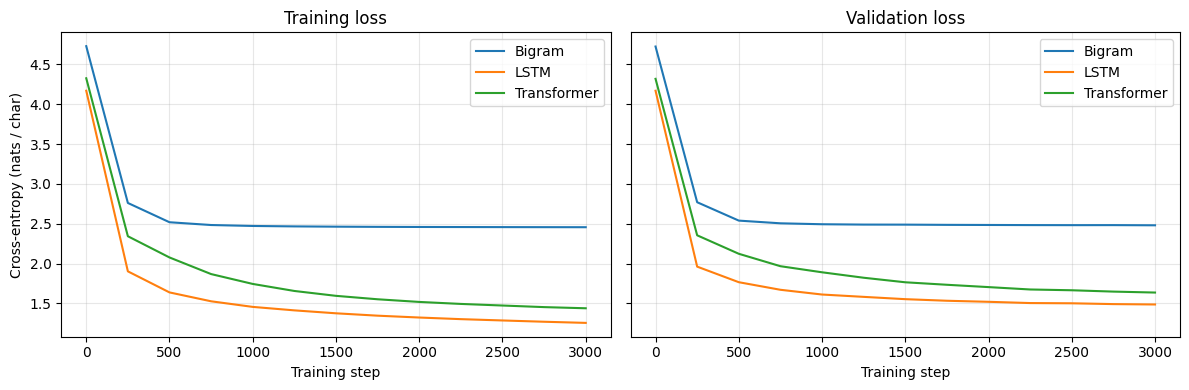

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for name, h in results.items():
    axes[0].plot(h['steps'], h['train_loss'], label=name)
    axes[1].plot(h['steps'], h['val_loss'], label=name)
for ax, title in zip(axes, ['Training loss', 'Validation loss']):
    ax.set_title(title)
    ax.set_xlabel('Training step')
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel('Cross-entropy (nats / char)')
fig.tight_layout()
fig.savefig('results/loss_curves.png', dpi=150)
plt.show()

## 10. Generated text samples

Each model generates 500 characters from the same prompt (a newline, i.e. the start of a speech), with the same temperature (0.8) and the same sampling seed. The bigram model only ever looks at the last character; the LSTM and transformer see up to 128 characters of context.

In [10]:
samples = {}
for name, model, context in [('Bigram', bigram, 1), ('LSTM', lstm, CFG.block_size),
                             ('Transformer', transformer, CFG.block_size)]:
    samples[name] = generate(model, context_len=context)
    with open(f'results/sample_{name.lower()}.txt', 'w', encoding='utf-8') as f:
        f.write(samples[name])
    print(f"{'=' * 25} {name} {'=' * 25}\n{samples[name]}\n")

========================= Bigram =========================



CEThef trid owind t s s, be mad ser bube t e anthand my d gatangs ar hthar us he he.
War dilasoate ar ce my.

Handarom orour
Yowhavetof is h ble mil ndilll,

Windee senghin lat Heriliovets, and t l nghire tranousel lind te llllishe ce hiry pthar aiss hew y.
Herinde n Boupetelaves homy y wod methake o Windo when eringhee ath dourive we higend t so mower; th

AN ad nthrurt f s ar irist m:

Thin maleronthefar Pre?

Whio myound sea!
KENobus ar adsal thes are thinin cour ay aney IOUSts I f my ce hy

========================= LSTM =========================

And they be done and in the times are boar
Upon my rude the gates such back, unquiet.

PAULINA:
Have you not hear's a wizonour
Your proceeding both! What little misters, I intent;
From overseen the longer in wants, less doth he
like you with a childish hew you love.

ROMEO:
I will not be sworn to again the king,
Cominalent to do this cheek; and poor mine;
When that noble trust 

## 11. How much does each model use its context?

The average validation loss is broken down by **position inside the 128-character window**. At position 0 every model has seen only one character, so all three should be similar. A model that uses longer context keeps lowering its loss as the position increases; the bigram model stays flat because it never looks back further than one character. Comparing how far down the LSTM and transformer curves go shows how much each one gains from extra context.

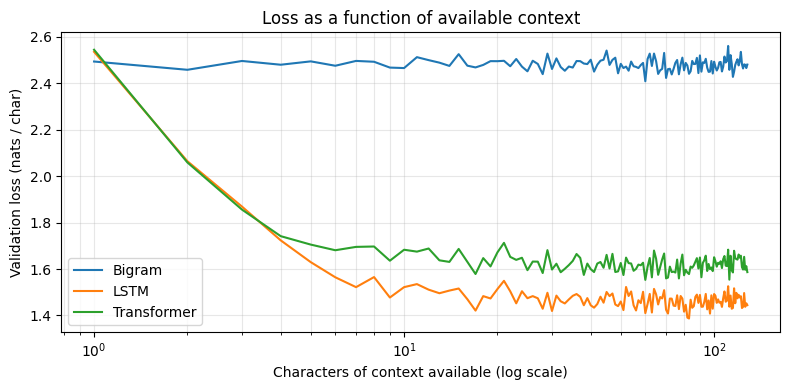

Bigram       loss with 1 char: 2.494   with 8: 2.493   with 32: 2.470   with 128: 2.481
LSTM         loss with 1 char: 2.536   with 8: 1.565   with 32: 1.461   with 128: 1.444
Transformer  loss with 1 char: 2.545   with 8: 1.697   with 32: 1.586   with 128: 1.587


In [11]:
@torch.no_grad()
def loss_by_position(model):
    """Mean validation cross-entropy at each position of the context window.

    Args:
        model (nn.Module): Trained language model.

    Returns:
        np.ndarray: Shape (block_size,), loss at positions 0..block_size-1.
    """
    model.eval()
    per_position = []
    for x, y in EVAL_BATCHES['val']:
        logits, _ = model(x)
        loss = F.cross_entropy(logits.reshape(-1, VOCAB_SIZE), y.reshape(-1), reduction='none')
        per_position.append(loss.view(x.shape).mean(dim=0).cpu().numpy())
    model.train()
    return np.mean(per_position, axis=0)


position_loss = {name: loss_by_position(m)
                 for name, m in [('Bigram', bigram), ('LSTM', lstm), ('Transformer', transformer)]}

fig, ax = plt.subplots(figsize=(8, 4))
for name, curve in position_loss.items():
    ax.plot(np.arange(1, CFG.block_size + 1), curve, label=name)
ax.set_xscale('log')
ax.set_xlabel('Characters of context available (log scale)')
ax.set_ylabel('Validation loss (nats / char)')
ax.set_title('Loss as a function of available context')
ax.grid(alpha=0.3, which='both')
ax.legend()
fig.tight_layout()
fig.savefig('results/loss_by_context.png', dpi=150)
plt.show()

for name, curve in position_loss.items():
    print(f"{name:<12} loss with 1 char: {curve[0]:.3f}   "
          f"with 8: {curve[7]:.3f}   with 32: {curve[31]:.3f}   with 128: {curve[-1]:.3f}")

## 12. What is attention looking at?

The heatmaps show the attention weights of each head in the **last** transformer layer for a 64-character validation snippet. Row *t* is the position being predicted from; bright cells show which earlier characters it draws information from. Look for heads that attend to the immediately preceding characters (local, n-gram-like patterns) and heads that reach back to specific earlier characters such as the start of the line, a space, or a repeated word.

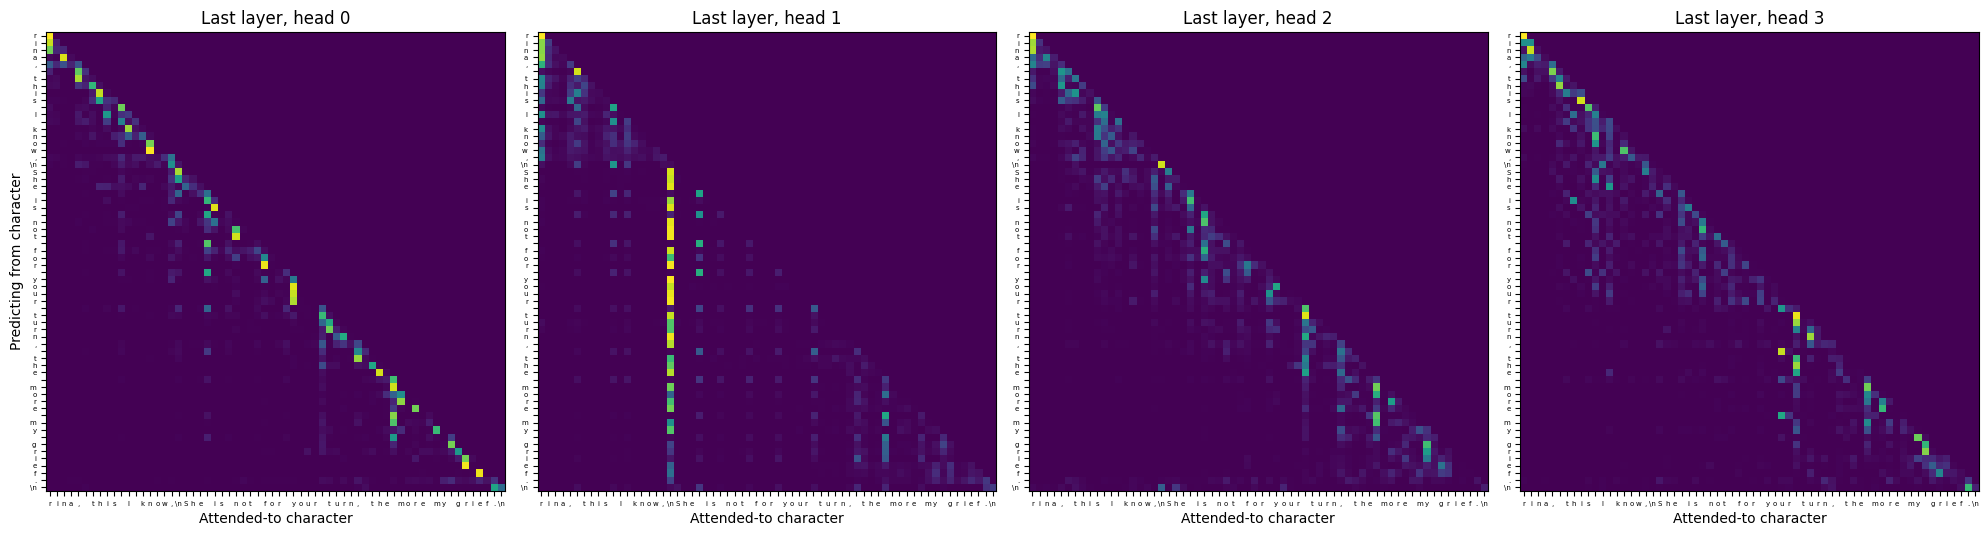

'rina, this I know,\nShe is not for your turn, the more my grief.\n'


In [12]:
snippet = val_data[1000:1064].unsqueeze(0).to(DEVICE)
transformer.eval()
with torch.no_grad():
    transformer(snippet)
attention = transformer.blocks[-1].attn.last_attention[0].cpu()   # (heads, T, T)
transformer.train()

labels = [repr(c)[1:-1] for c in decode(snippet[0].tolist())]
n_heads = attention.shape[0]
fig, axes = plt.subplots(1, n_heads, figsize=(5 * n_heads, 5))
for h, ax in enumerate(np.atleast_1d(axes)):
    ax.imshow(attention[h], cmap='viridis')
    ax.set_title(f'Last layer, head {h}')
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=5)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=5)
    ax.set_xlabel('Attended-to character')
axes[0].set_ylabel('Predicting from character')
fig.tight_layout()
fig.savefig('results/attention_heads.png', dpi=150)
plt.show()
print(repr(decode(snippet[0].tolist())))

## 13. Qualitative analysis

### Completed results table

| Model | Params | Train Loss | Validation Loss | Val Perplexity | Training Time (s) | Generated Text Quality | Notes |
|---|---:|---:|---:|---:|---:|---|---|
| Bigram | 4,225 | 2.4570 | 2.4810 | 11.95 | 4.6 | Low | Matches the closed-form count bigram (2.486), so it reached the best any bigram can do. Plausible letter pairs, a few short real words. |
| LSTM | 946,625 | 1.2567 | 1.4876 | 4.43 | 74.0 | High | Best loss. Real speaker names and mostly real words. Largest train–val gap (0.23). |
| Transformer | 826,433 | 1.4401 | 1.6373 | 5.14 | 96.0 | Medium | Correct play format but more invented words. Loss was still falling at step 3,000. |

Device: CUDA GPU, 3,000 steps, batch 64, context 128 characters.

**1. Which model performed best?**
The LSTM, with a validation loss of 1.488 (perplexity 4.43), followed by the transformer at 1.637 (perplexity 5.14) and the bigram at 2.481 (perplexity 11.95). Both neural models cut the bigram's loss by more than a third. The LSTM also had the largest gap between training and validation loss (0.23, vs. 0.20 for the transformer), so it was starting to memorize the training text more.

**2. Which model trained fastest?**
The bigram, by far: 4.6 seconds in total, and its loss was within 0.03 of its final value by step 750. The LSTM took 74 seconds and the transformer 96 seconds, about 1.3 times as long per step as the LSTM. The transformer also learned more slowly per step: at step 250 its validation loss was 2.36 vs. 1.96 for the LSTM, and it was still dropping noticeably at the end (0.029 over the last 500 steps, about twice the LSTM's 0.015).

**3. Which model generated the most realistic text?**
The LSTM. Its sample uses real character names from the plays (PAULINA, ROMEO, HENRY BOLINGBROKE, MENENIUS), puts them in the correct `NAME:` format, and most words are real ("I will not be sworn to again the king"). The transformer also learned the format (`Clown:`, `JOHN OF AUMERLE:`) and line lengths, but it produces more invented words ("gatests", "abself", "Englanded") and repetitive filler ("and be not and be"). The bigram produces word-shaped fragments ("CEThef trid owind") with only short common words like "my", "he", and "the" coming out right.

**4. What did the transformer improve compared to the other models?**
Compared to the bigram, a lot: the loss-by-context plot shows the transformer's loss dropping from 2.545 with one character of context to 1.697 with 8 and 1.586 with 32, while the bigram stays flat around 2.48 because it can't use more than one character. Compared to the LSTM, it did not improve in this run. The two curves are almost identical for the first 3–4 characters, but then the transformer levels off around 1.59 after about 30 characters while the LSTM keeps improving to 1.44. So in this small, short training run, the transformer did not get extra value out of long context. Its advantage over the LSTM was mainly that its behavior is easier to inspect (see question 6).

**5. Was the improvement worth the added complexity?**
Over the bigram, clearly yes: a 0.84 drop in validation loss turned letter soup into recognizable Shakespeare-style text. The transformer over the LSTM was not worth it at this scale: it was more code, about 30% slower to train, and gave a worse loss with a similar number of parameters. One likely reason is that 3,000 steps with a constant learning rate and no warmup is too short for the transformer, since its loss was still falling twice as fast as the LSTM's at the end. Another is that character-level text depends mostly on the last few characters, which an LSTM handles well. A longer run would be the next experiment to see if the transformer catches up.

**6. What did I learn about attention?**
The four heads in the last layer learned clearly different jobs. Head 0 is almost a single bright diagonal just below the main diagonal: each position mostly looks at the character right before it, a local, bigram-like pattern. Head 1 has a bright vertical stripe: after the line break in "this I know,\nShe is not for your turn", almost every position in the new line attends to the start of that line, which gives the model a way to track where it is in a line (useful for knowing when to break). Heads 2 and 3 spread their attention over a few recent characters, with brighter spots at spaces and punctuation, which looks like tracking the start of the current word. Attention is not just a blur of "look at everything": each head learns its own rule about which earlier characters matter, and you can see it.

## 14. Final reflection

**After comparing bigram, non-transformer, and transformer models, what do you think makes transformers powerful for language modeling?**

I think what makes transformers powerful is that attention gives every position a direct path to any earlier position, and the model learns which ones to use. The bigram model can't look back at all, and the LSTM has to squeeze everything it has read into one hidden state that is rewritten at every step. Attention instead lets each prediction pick out the characters that matter, and different heads learn different rules: in my heatmaps one head copies the previous character while another keeps pointing at the start of the current line. Because all positions are processed at once rather than one after another, this design can also be scaled to much larger models and datasets than an LSTM can. My results also showed the other side: with about 800K parameters and 3,000 training steps, the LSTM still won, and the transformer stopped benefiting from context after about 30 characters. So attention is not automatically better. Its strength shows up when there is enough data, model size, and training for it to learn which connections matter.
